# CSE428 Project 
23201180 S M Deedarul Alam



In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Using device:", device)
if device == 'cuda':
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))


PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 3060
CUDA version: 12.8
Using device: cuda
GPU: NVIDIA GeForce RTX 3060
VRAM (GB): 12.9


## 2. Config


In [ ]:
IMG_SIZE = 128        
BATCH_SIZE = 16
NUM_CLASSES = 37       
DATA_ROOT = "./data"    
SEED = 125             

torch.manual_seed(SEED)
np.random.seed(SEED)


## 3. Downloading the dataset



In [ ]:
trainval_raw = OxfordIIITPet(
    root=DATA_ROOT,
    split="trainval",
    target_types=["category", "segmentation"],
    download=True,
)

test_raw = OxfordIIITPet(
    root=DATA_ROOT,
    split="test",
    target_types=["category", "segmentation"],
    download=True,
)

print("trainval size:", len(trainval_raw))
print("test size:", len(test_raw))
print("classes:", trainval_raw.classes[:5], "...")




trainval size: 3680
test size: 3669
classes: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle'] ...


## 4. Fixing the trimap masks




In [ ]:
def fix_trimap(trimap_array):
    return (trimap_array == 1) | (trimap_array == 3)
# Original mask
#    │
#    ├── 1 → foreground 
#    ├── 2 → background 
#    └── 3 → foreground 


## 5. Loading everything into arrays



In [ ]:
resize_img = transforms.Resize((IMG_SIZE, IMG_SIZE))  #128 × 128
resize_mask = transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.NEAREST)


def read_data(raw_dataset):
    x_list, mask_list, label_list = [], [], []
    for img, (label, trimap) in raw_dataset:
        img = resize_img(img.convert("RGB"))
        trimap = resize_mask(trimap)

        img_arr = np.array(img, dtype=np.float32) / 255.0          # (H, W, 3), scaled to [0,1]
        trimap_arr = np.array(trimap)                               # (H, W), values in {1,2,3}
        mask_arr = fix_trimap(trimap_arr)                            # (H, W), boolean

        x_list.append(img_arr)
        mask_list.append(mask_arr)
        label_list.append(label)

    x = np.stack(x_list)               # (N, H, W, 3)  
    y_mask = np.stack(mask_list)        # (N, H, W)
    y_label = np.array(label_list)      # (N,)
    return x, y_mask, y_label
# Image → x_list
# Mask  → mask_list
# Breed → label_list

print("Loading trainval (this takes a few minutes the first time)...")
x_trainval, mask_trainval, y_trainval = read_data(trainval_raw)

print("Loading test...")
x_test, mask_test, y_test = read_data(test_raw)

print(x_trainval.shape, mask_trainval.shape, y_trainval.shape)


Loading trainval (this takes a few minutes the first time)...
Loading test...
(3680, 128, 128, 3) (3680, 128, 128) (3680,)


## 6. Train / val split and normalization




In [13]:
train_idx, val_idx = train_test_split(
    np.arange(len(y_trainval)),
    test_size=0.15,
    stratify=y_trainval,
    random_state=SEED,
)

x_train, x_val = x_trainval[train_idx], x_trainval[val_idx]
y_train, y_val = y_trainval[train_idx], y_trainval[val_idx]
mask_train, mask_val = mask_trainval[train_idx], mask_trainval[val_idx]

# z-score normalization, per-channel, using TRAIN stats only
train_mean = x_train.mean(axis=(0, 1, 2), keepdims=True)
train_std = x_train.std(axis=(0, 1, 2), keepdims=True) + 1e-4

x_train = (x_train - train_mean) / train_std
x_val = (x_val - train_mean) / train_std
x_test_norm = (x_test - train_mean) / train_std

print("train:", x_train.shape, " val:", x_val.shape, " test:", x_test_norm.shape)

#                  TRAINVAL
#                     │
#           ┌─────────┴─────────┐
#           │                   │
#         85%                  15%
#           │                   │
#        TRAIN              VALIDATION
#           │                   │
#     ┌─────┴─────┐       ┌─────┴─────┐
#     │           │       │           │
#   images      labels   images      labels
#     │           │       │           │
#  x_train     y_train  x_val       y_val


train: (3128, 128, 128, 3)  val: (552, 128, 128, 3)  test: (3669, 128, 128, 3)


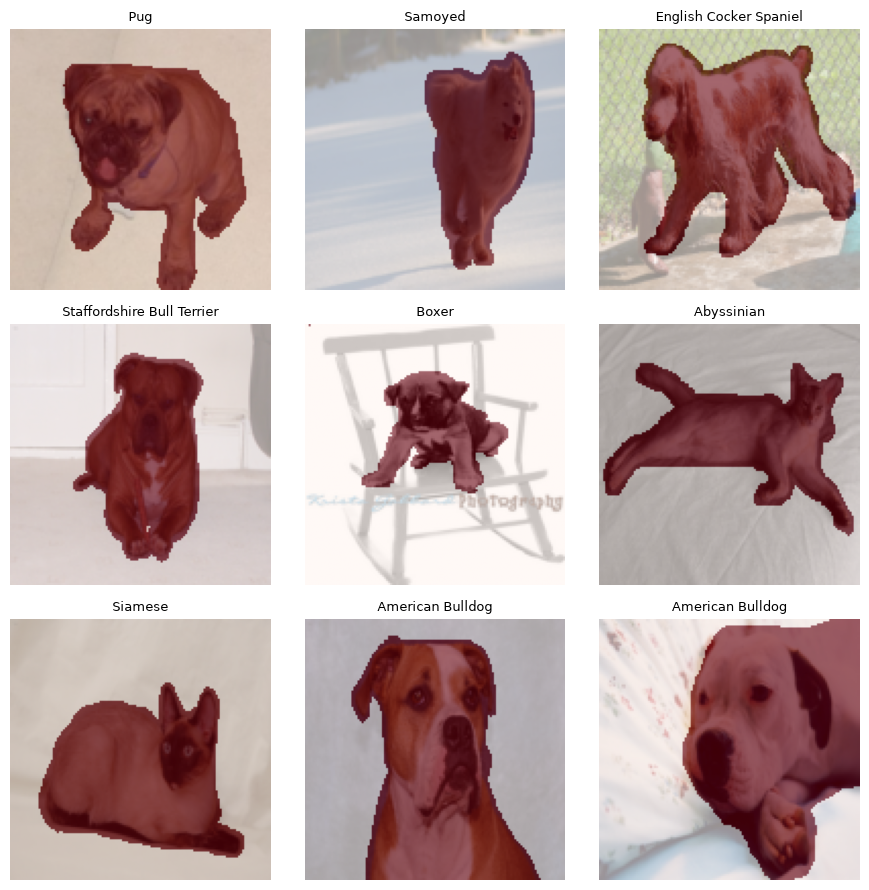

In [14]:
def show_overlay(ax, image, mask, label_name, alpha=0.6):
    ax.imshow(image)
    ax.imshow(mask, cmap='Reds', alpha=alpha)
    ax.set_title(label_name, fontsize=9)
    ax.axis('off')

def plot_grid(x, masks, labels, class_names, n=9, seed=None):
    rng = np.random.default_rng(seed)
    idxs = rng.choice(len(x), size=n, replace=False)
    rows = cols = int(np.sqrt(n))
    fig, axes = plt.subplots(rows, cols, figsize=(9, 9))
    for ax, idx in zip(axes.flatten(), idxs):
        # undo normalization just for display purposes
        # original = normalized × std + mean
        img_display = x[idx] * train_std[0] + train_mean[0]
        img_display = np.clip(img_display, 0, 1)
        show_overlay(ax, img_display, masks[idx], class_names[labels[idx]])
    plt.tight_layout()
    plt.show()

plot_grid(x_train, mask_train, y_train, trainval_raw.classes, n=9, seed=378)


## 1. BatchLoader





RandomHorizontalFlip
        ↓
RandomRotation
        ↓
ColorJitter
        ↓
RandomErasing

In [ ]:
class BatchLoaderAugmented():  # For training only
    def __init__(self, x, y_mask, y_label, shuffle=True, batch_size=16, device='cpu'):
        self.x = x
        self.y_mask = y_mask
        self.y_label = y_label
        self.batch_size = batch_size
        self.len = np.ceil(len(x) / batch_size).astype(int)
        self.indices = np.arange(len(x))
        self.shuffle = shuffle
        if self.shuffle:
            np.random.shuffle(self.indices)
        self.iter = 0
        self.device = device

        
        self.mean = torch.tensor(train_mean.squeeze(), dtype=torch.float32).view(3, 1, 1)
        self.std = torch.tensor(train_std.squeeze(), dtype=torch.float32).view(3, 1, 1)

        # Augmentation pipeline
        self.augmentation = transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=15),
            transforms.ColorJitter(
                brightness=0.2,
                contrast=0.2,
                saturation=0.2
            ),
            transforms.RandomErasing(p=0.3, scale=(0.02, 0.1)),
        ])

    def next(self, task='both'):
        start = self.iter * self.batch_size
        if self.iter < self.len - 1:
            idx = self.indices[start:start + self.batch_size]
            self.iter += 1
        else:
            idx = self.indices[start:]
            self.iter = 0
            if self.shuffle:
                np.random.shuffle(self.indices)

        batch_x = torch.tensor(
            self.x[idx],
            dtype=torch.float32
        )

        augmented_images = []
        for image in batch_x:
            
            image = image.permute(2, 0, 1) 

            
            image = image * self.std + self.mean
            image = image.clamp(0, 1)

            image = self.augmentation(image)

            image = (image - self.mean) / self.std

            image = image.permute(1, 2, 0) 
            augmented_images.append(image)

        batch_x = torch.stack(augmented_images)

        # Move augmented images to GPU
        batch_x = batch_x.to(self.device)

        if task == 'classification':
            return batch_x, torch.tensor(
                self.y_label[idx],
                dtype=torch.long,
                device=self.device
            )
        elif task == 'segmentation':
            return batch_x, torch.tensor(
                self.y_mask[idx],
                dtype=torch.float32,
                device=self.device
            )
        elif task == 'both':
            by_label = torch.tensor(
                self.y_label[idx],
                dtype=torch.long,
                device=self.device
            )
            by_mask = torch.tensor(
                self.y_mask[idx],
                dtype=torch.float32,
                device=self.device
            )
            return batch_x, by_label, by_mask

In [ ]:
class BatchLoaderAugmented(): 

    def __init__(self, x, y_mask, y_label,shuffle=True, batch_size=16, device='cpu'):

        self.x = x
        self.y_mask = y_mask
        self.y_label = y_label
        self.batch_size = batch_size
        self.len = np.ceil(len(x) / batch_size).astype(int)
        self.indices = np.arange(len(x))
        self.shuffle = shuffle

        if self.shuffle:
            np.random.shuffle(self.indices)

        self.iter = 0
        self.device = device

        self.mean = torch.tensor(
            train_mean.squeeze(),
            dtype=torch.float32
        ).view(3, 1, 1)

        self.std = torch.tensor(
            train_std.squeeze(),
            dtype=torch.float32
        ).view(3, 1, 1)

        # ------------------------------------------------
        # Geometric augmentations
        # These must be applied to BOTH image and mask
        # ------------------------------------------------
        self.geometric_augmentation = transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(
                degrees=15,
                interpolation=transforms.InterpolationMode.BILINEAR
            )
        ])

        # ------------------------------------------------
        # Appearance augmentations
        # These are applied ONLY to the image
        # ------------------------------------------------
        self.image_augmentation = transforms.Compose([
            transforms.ColorJitter(
                brightness=0.2,
                contrast=0.2,
                saturation=0.2
            ),
            transforms.RandomErasing(
                p=0.3,
                scale=(0.02, 0.1)
            )
        ])

    def next(self, task='both'):

        # ---------------------------------------------
        # Select the next batch
        # ---------------------------------------------
        start = self.iter * self.batch_size

        if self.iter < self.len - 1:

            idx = self.indices[
                start:start + self.batch_size
            ]

            self.iter += 1

        else:

            idx = self.indices[start:]

            self.iter = 0

            if self.shuffle:
                np.random.shuffle(self.indices)

        # ---------------------------------------------
        # Convert images to tensors
        # ---------------------------------------------
        batch_x = torch.tensor(
            self.x[idx],
            dtype=torch.float32
        )

        # Convert masks to tensors
        batch_mask = torch.tensor(
            self.y_mask[idx],
            dtype=torch.float32
        )

        augmented_images = []
        augmented_masks = []

        # ---------------------------------------------
        # Process each image and mask
        # ---------------------------------------------
        for image, mask in zip(batch_x, batch_mask):

            image = image.permute(2, 0, 1)

            if mask.ndim == 2:
                mask = mask.unsqueeze(0)

    
            # Undo image normalization
            
            image = image * self.std + self.mean
            image = image.clamp(0, 1)


            # Random horizontal flip
            if torch.rand(1) < 0.5:
                image = transforms.functional.hflip(image)
                mask = transforms.functional.hflip(mask)

            # Random rotation
            angle = transforms.RandomRotation.get_params(
                [-15, 15]
            )

            image = transforms.functional.rotate(
                image,
                angle,
                interpolation=transforms.InterpolationMode.BILINEAR
            )

            
            mask = transforms.functional.rotate(
                mask,
                angle,
                interpolation=transforms.InterpolationMode.NEAREST
            )

            
            image = self.image_augmentation(image)

            image = (image - self.mean) / self.std

            image = image.permute(1, 2, 0)

            mask = mask.squeeze(0)

            augmented_images.append(image)
            augmented_masks.append(mask)

        batch_x = torch.stack(augmented_images)
        batch_mask = torch.stack(augmented_masks)

    
        batch_x = batch_x.to(self.device)
        batch_mask = batch_mask.to(self.device)

        
        if task == 'classification':

            return batch_x, torch.tensor(
                self.y_label[idx],
                dtype=torch.long,
                device=self.device
            )

        
        elif task == 'segmentation':

            return batch_x, batch_mask

        
        elif task == 'both':

            by_label = torch.tensor(
                self.y_label[idx],
                dtype=torch.long,
                device=self.device
            )

            return batch_x, by_label, batch_mask

In [9]:
class BatchLoader():
    def __init__(self, x, y_mask, y_label, shuffle=True, batch_size=16, device='cuda'):
        self.x = x
        self.y_mask = y_mask
        self.y_label = y_label
        self.batch_size = batch_size
        self.len = np.ceil(len(x) / batch_size).astype(int)
        self.indices = np.arange(len(x))
        self.shuffle = shuffle
        if self.shuffle:
            np.random.shuffle(self.indices)
        self.iter = 0
        self.device = device

    def next(self, task='both'):
        start = self.iter * self.batch_size
        if self.iter < self.len - 1:
            idx = self.indices[start:start + self.batch_size]
            self.iter += 1
        else:
            idx = self.indices[start:]
            self.iter = 0
            if self.shuffle:
                np.random.shuffle(self.indices)

        batch_x = torch.tensor(self.x[idx], dtype=torch.float32, device=self.device)

        if task == 'classification':
            return batch_x, torch.tensor(self.y_label[idx], dtype=torch.long, device=self.device)
        elif task == 'segmentation':
            return batch_x, torch.tensor(self.y_mask[idx], dtype=torch.float32, device=self.device)
        elif task == 'both':
            by_label = torch.tensor(self.y_label[idx], dtype=torch.long, device=self.device)
            by_mask = torch.tensor(self.y_mask[idx], dtype=torch.float32, device=self.device)
            return batch_x, by_label, by_mask

## 2.U-Net
It consists of the repeated application of two 3x3 convolutions (unpadded convolutions)[padded]
Each followed by a rectified linear unit (ReLU) and a 2x2 max pooling operation with stride 2





In [ ]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding='same'),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding='same'),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)


class UNetEncoder(nn.Module):
    def __init__(self, in_channels, first_out_channel=32):
        super().__init__()
        self.enc1 = ConvBlock(in_channels, first_out_channel)           # 32
        self.enc2 = ConvBlock(first_out_channel, first_out_channel*2)    # 64
        self.enc3 = ConvBlock(first_out_channel*2, first_out_channel*4)  # 128
        self.enc4 = ConvBlock(first_out_channel*4, first_out_channel*8)  # 256
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x1 = self.enc1(x)              # 32 ch  @ IMG_SIZE
        x2 = self.enc2(self.pool(x1))  # 64 ch  @ IMG_SIZE/2
        x3 = self.enc3(self.pool(x2))  # 128 ch @ IMG_SIZE/4
        x4 = self.enc4(self.pool(x3))  # 256 ch @ IMG_SIZE/8
        return x1, x2, x3, x4


class UNetBottleneck(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.enc = ConvBlock(in_channels, in_channels*2)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        return self.enc(self.pool(x))   # 512 ch @ IMG_SIZE/16


class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = nn.Sequential(
            nn.Conv2d(2*out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
        )

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)


class UNetDecoder(nn.Module):
    def __init__(self, in_channels=512):
        super().__init__()
        self.decode1 = DecoderBlock(in_channels, in_channels//2)      # 512 -> 256
        self.decode2 = DecoderBlock(in_channels//2, in_channels//4)   # 256 -> 128
        self.decode3 = DecoderBlock(in_channels//4, in_channels//8)   # 128 -> 64
        self.decode4 = DecoderBlock(in_channels//8, in_channels//16)  # 64  -> 32
        self.final_conv = nn.Conv2d(in_channels//16, 1, kernel_size=1)

    def forward(self, x5, x4, x3, x2, x1):
        x4 = self.decode1(x5, x4)
        x3 = self.decode2(x4, x3)
        x2 = self.decode3(x3, x2)
        x1 = self.decode4(x2, x1)
        return self.final_conv(x1).squeeze(1)  


## 3. Losses and metrics


In [ ]:
class DiceLoss(nn.Module):
    def __init__(self, epsilon=1e-6):
        super().__init__()
        self.epsilon = epsilon

    def forward(self, preds, targets):
        preds = torch.sigmoid(preds)

        preds = preds.view(preds.shape[0], -1)
        targets = targets.view(targets.shape[0], -1)

        intersection = (preds * targets).sum(dim=1)

        dice = (
            2 * intersection + self.epsilon
        ) / (
            preds.sum(dim=1) + targets.sum(dim=1) + self.epsilon
        )

        return 1 - dice.mean()


def calculate_iou(y_pred, y_true, threshold=0.5, eps=1e-6):
    y_pred = torch.sigmoid(y_pred)
    y_pred = (y_pred > threshold).float()             
    y_pred = y_pred.view(y_pred.shape[0], -1)         
    y_true = y_true.view(y_true.shape[0], -1)
    intersection = (y_pred * y_true).sum(dim=1)
    union = y_pred.sum(dim=1) + y_true.sum(dim=1) - intersection
    return ((intersection + eps) / (union + eps)).mean()   


def dice_coefficient(y_pred, y_true, threshold=0.5, eps=1e-6):
    y_pred = torch.sigmoid(y_pred)
    y_pred = (y_pred > threshold).float()
    y_pred = y_pred.view(y_pred.shape[0], -1)
    y_true = y_true.view(y_true.shape[0], -1)
    intersection = (y_pred * y_true).sum(dim=1)
    return ((2. * intersection + eps) / (y_pred.sum(dim=1) + y_true.sum(dim=1) + eps)).mean()


def pixel_accuracy(y_pred, y_true, threshold=0.5):
    y_pred = torch.sigmoid(y_pred)
    y_pred = (y_pred > threshold).float()
    correct = (y_pred == y_true.float()).float().sum()
    return (correct / y_true.numel()).item()        


def classification_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    return acc, precision, recall, f1


## 4. Classifier head




In [54]:
class Classifier(nn.Module):
    def __init__(self, in_channels=512, num_classes=37, p=0.4):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, in_channels, 3, padding='same')
        self.bn1 = nn.BatchNorm2d(in_channels)
        self.conv2 = nn.Conv2d(in_channels, in_channels // 2, 3, padding='same')
        self.bn2 = nn.BatchNorm2d(in_channels // 2)
        self.conv3 = nn.Conv2d(in_channels // 2, num_classes, 3, padding='same')
        self.dropout = nn.Dropout(p)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.bn1(self.conv1(x))), 2, stride=2)   # 8x8 -> 4x4
        x = self.dropout(x)
        x = F.max_pool2d(F.relu(self.bn2(self.conv2(x))), 2, stride=2)   # 4x4 -> 2x2
        x = self.dropout(x)
        x = F.adaptive_avg_pool2d(self.conv3(x), (1, 1)).squeeze((-1, -2))  # 2x2 -> 1x1 -> (N, num_classes)
        return x

## 5. Training the base U-Net + classifier jointly do not run




In [ ]:
encoder = UNetEncoder(3, 32).to(device)       
bottleneck = UNetBottleneck(256).to(device)    # matches enc4's 256 output channels
decoder = UNetDecoder(512).to(device)
classifier = Classifier(512, NUM_CLASSES).to(device)

train_loader = BatchLoaderAugmented(x_train, mask_train, y_train, shuffle=True, batch_size=BATCH_SIZE, device=device)
val_loader = BatchLoader(x_val, mask_val, y_val, shuffle=False, batch_size=BATCH_SIZE, device=device)

epochs = 30
# 3. OPTIMIZER
optim = torch.optim.AdamW(
    list(encoder.parameters()) +
    list(bottleneck.parameters()) +
    list(decoder.parameters()) +
    list(classifier.parameters()),
    lr=3e-4,          # was 1e-3
    weight_decay=0.05
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=epochs)

# 4. SEGMENTATION LOSSES


dice_loss = DiceLoss()
bce_loss = nn.BCEWithLogitsLoss()


# 5. CLASS WEIGHTS

class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
assert len(class_weights) == NUM_CLASSES, (
    f"Expected {NUM_CLASSES} classes in y_train, found {len(class_weights)}. "
    "A breed is missing from the training split -- check the stratified split in Part 1."
)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

# 6. CLASSIFICATION LOSS

classifier_loss_fn = nn.CrossEntropyLoss(weight=class_weights)


# 7. CHECKPOINT LOCATION
# ============================================================

CHECKPOINT_DIR = "checkpoints"

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "base_unet.pt"
)


# 8. TRAINING SETTINGS


for epoch in range(epochs):
    print(f"Epoch - {epoch + 1}")
    encoder.train(); bottleneck.train(); decoder.train(); classifier.train()

    train_bce = train_dice = train_iou = train_cls_loss = 0.0
    train_correct = train_samples = 0

    for i in range(train_loader.len):
        x, y_label, y_mask = train_loader.next('both')
        x = x.permute(0, 3, 1, 2)  

        x1, x2, x3, x4 = encoder(x)
        x5 = bottleneck(x4)
        y_pred_mask = decoder(x5, x4, x3, x2, x1)
        y_pred_label = classifier(x5)

        bce = bce_loss(y_pred_mask, y_mask)
        dice = dice_loss(y_pred_mask, y_mask)
        cls_loss = classifier_loss_fn(y_pred_label, y_label)
        loss = (0.2*bce + 0.8*dice)/2 + 0.3*cls_loss   

        train_bce += bce.item(); train_dice += dice.item()
        train_iou += calculate_iou(y_pred_mask, y_mask).item()
        train_cls_loss += cls_loss.item()
        train_correct += (y_pred_label.argmax(dim=1) == y_label).sum().item()
        train_samples += y_label.shape[0]

        optim.zero_grad()
        loss.backward()
        optim.step()

    print(f"  Train | BCE {train_bce/train_loader.len:.4f}  Dice {train_dice/train_loader.len:.4f}  "
          f"IoU {train_iou/train_loader.len:.4f}  ClsLoss {train_cls_loss/train_loader.len:.4f}  "
          f"Acc {train_correct/train_samples:.4f}")

    encoder.eval(); bottleneck.eval(); decoder.eval(); classifier.eval()
    val_bce = val_dice = val_iou = val_cls_loss = 0.0
    val_correct = val_samples = 0
     # VALIDATION

    with torch.no_grad():
        for i in range(val_loader.len):
            x, y_label, y_mask = val_loader.next('both')
            x = x.permute(0, 3, 1, 2)

            x1, x2, x3, x4 = encoder(x)
            x5 = bottleneck(x4)
            y_pred_mask = decoder(x5, x4, x3, x2, x1)
            y_pred_label = classifier(x5)

            val_bce += bce_loss(y_pred_mask, y_mask).item()
            val_dice += dice_loss(y_pred_mask, y_mask).item()
            val_iou += calculate_iou(y_pred_mask, y_mask).item()
            val_cls_loss += classifier_loss_fn(y_pred_label, y_label).item()
            val_correct += (y_pred_label.argmax(dim=1) == y_label).sum().item()
            val_samples += y_label.shape[0]

    print(f"  Val   | BCE {val_bce/val_loader.len:.4f}  Dice {val_dice/val_loader.len:.4f}  "
          f"IoU {val_iou/val_loader.len:.4f}  ClsLoss {val_cls_loss/val_loader.len:.4f}  "
          f"Acc {val_correct/val_samples:.4f}\n")
    # SAVE CHECKPOINT

    scheduler.step()
    print("Learning rate:", optim.param_groups[0]["lr"])
    torch.save({

        # IMPORTANT:
        # epoch + 1 means this epoch is completed
        'epoch': epoch + 1,

        # Model parameters
        'encoder': encoder.state_dict(),

        'bottleneck': bottleneck.state_dict(),

        'decoder': decoder.state_dict(),

        'classifier': classifier.state_dict(),

        # Optimizer state
        'optim': optim.state_dict(),

    }, CHECKPOINT_PATH)
    print(f"Checkpoint saved: {CHECKPOINT_PATH}")
    print()



Epoch - 1
  Train | BCE 0.4767  Dice 0.3660  IoU 0.5812  ClsLoss 3.6413  Acc 0.0432
  Val   | BCE 0.5851  Dice 0.3179  IoU 0.5954  ClsLoss 3.6153  Acc 0.0634

Learning rate: 0.00029917828430524096
Checkpoint saved: checkpoints\base_unet.pt

Epoch - 2
  Train | BCE 0.4319  Dice 0.2737  IoU 0.6517  ClsLoss 3.4799  Acc 0.0623
  Val   | BCE 0.3990  Dice 0.2322  IoU 0.6923  ClsLoss 3.8347  Acc 0.0543

Learning rate: 0.0002967221401100708
Checkpoint saved: checkpoints\base_unet.pt

Epoch - 3
  Train | BCE 0.4088  Dice 0.2368  IoU 0.6826  ClsLoss 3.2875  Acc 0.0975
  Val   | BCE 0.3509  Dice 0.2099  IoU 0.7181  ClsLoss 3.1243  Acc 0.1178

Learning rate: 0.00029265847744427303
Checkpoint saved: checkpoints\base_unet.pt

Epoch - 4
  Train | BCE 0.3777  Dice 0.2110  IoU 0.7085  ClsLoss 3.1214  Acc 0.1240
  Val   | BCE 0.3605  Dice 0.2013  IoU 0.7201  ClsLoss 3.1505  Acc 0.1196

Learning rate: 0.0002870318186463901
Checkpoint saved: checkpoints\base_unet.pt

Epoch - 5
  Train | BCE 0.3686  Dice 0

**Without augmentation dropout and rebalancing class_loss contribution

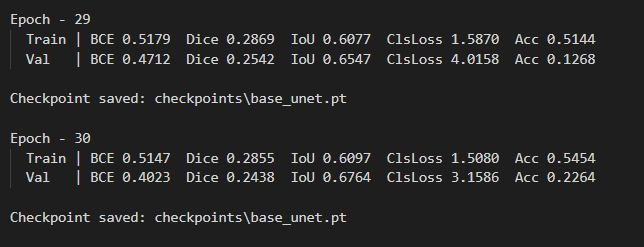

## 6. Full evaluation on train / val / test



In [38]:
def evaluate(loader, encoder, bottleneck, decoder, classifier):
    encoder.eval();bottleneck.eval(); decoder.eval(); classifier.eval()
    ious, dices, pix_accs = [], [], []
    all_true, all_pred = [], []

    with torch.no_grad():
        for i in range(loader.len):
            x, y_label, y_mask = loader.next('both')
            x = x.permute(0, 3, 1, 2)

            x1, x2, x3, x4 = encoder(x)
            x5 = bottleneck(x4)
            y_pred_mask = decoder(x5, x4, x3, x2, x1)
            y_pred_label = classifier(x5)

            ious.append(calculate_iou(y_pred_mask, y_mask).item())
            dices.append(dice_coefficient(y_pred_mask, y_mask).item())
            pix_accs.append(pixel_accuracy(y_pred_mask, y_mask))
            all_true.extend(y_label.cpu().numpy().tolist())
            all_pred.extend(y_pred_label.argmax(dim=1).cpu().numpy().tolist())

    acc, precision, recall, f1 = classification_metrics(all_true, all_pred)
    return {
        "mIoU": np.mean(ious), "Dice": np.mean(dices), "PixelAcc": np.mean(pix_accs),
        "Accuracy": acc, "Precision": precision, "Recall": recall, "F1": f1,
    }


test_loader = BatchLoader(x_test_norm, mask_test, y_test, shuffle=False, batch_size=BATCH_SIZE, device=device)
train_eval_loader = BatchLoader(x_train, mask_train, y_train, shuffle=False, batch_size=BATCH_SIZE, device=device)

base_unet_results = {
    "train": evaluate(train_eval_loader, encoder, bottleneck, decoder, classifier),
    "val": evaluate(val_loader, encoder, bottleneck, decoder, classifier),
    "test": evaluate(test_loader, encoder, bottleneck, decoder, classifier),
}

for split, metrics in base_unet_results.items():
    print(f"{split}: " + ", ".join(f"{k}={v:.4f}" for k, v in metrics.items()))


train: mIoU=0.8419, Dice=0.9092, PixelAcc=0.9323, Accuracy=0.8692, Precision=0.8754, Recall=0.8696, F1=0.8691
val: mIoU=0.8291, Dice=0.9000, PixelAcc=0.9275, Accuracy=0.5707, Precision=0.5988, Recall=0.5714, F1=0.5701
test: mIoU=0.8213, Dice=0.8949, PixelAcc=0.9213, Accuracy=0.5296, Precision=0.5486, Recall=0.5297, F1=0.5292




 `AttentionGate


In [51]:
import pandas as pd
class AttentionGate(nn.Module):
    def __init__(self, gate_channels, skip_channels, inter_channels):
        super().__init__()
        self.W_gate = nn.Sequential(
            nn.Conv2d(gate_channels, inter_channels, kernel_size=1),
            nn.BatchNorm2d(inter_channels),
        )
        self.W_skip = nn.Sequential(
            nn.Conv2d(skip_channels, inter_channels, kernel_size=1),
            nn.BatchNorm2d(inter_channels),
        )
        self.psi = nn.Sequential(
            nn.Conv2d(inter_channels, 1, kernel_size=1),
            nn.BatchNorm2d(1),
            nn.Sigmoid(),
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, gate, skip):
        g1 = self.W_gate(gate)
        g1 = F.interpolate(g1, size=skip.shape[2:], mode='bilinear', align_corners=False)
        x1 = self.W_skip(skip)
        attn = self.psi(self.relu(g1 + x1))
        return skip * attn

## 2. Attention decoder block and decoder



class AttnDecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.attn = AttentionGate(
            gate_channels=in_channels, skip_channels=out_channels, inter_channels=out_channels // 2
        )
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = nn.Sequential(
            nn.Conv2d(2*out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
        )

    def forward(self, x, skip):
        gated_skip = self.attn(x, skip)   # gate signal = coarser feature map, before upsampling
        x = self.up(x)
        x = torch.cat([gated_skip, x], dim=1)
        return self.conv(x)


class AttentionUNetDecoder(nn.Module):
    def __init__(self, in_channels=512):
        super().__init__()
        self.decode1 = AttnDecoderBlock(in_channels, in_channels//2)
        self.decode2 = AttnDecoderBlock(in_channels//2, in_channels//4)
        self.decode3 = AttnDecoderBlock(in_channels//4, in_channels//8)
        self.decode4 = AttnDecoderBlock(in_channels//8, in_channels//16)
        self.final_conv = nn.Conv2d(in_channels//16, 1, kernel_size=1)

    def forward(self, x5, x4, x3, x2, x1):
        x4 = self.decode1(x5, x4)
        x3 = self.decode2(x4, x3)
        x2 = self.decode3(x3, x2)
        x1 = self.decode4(x2, x1)
        return self.final_conv(x1).squeeze(1)


## 3. Training the Attention U-Net DONT run




In [55]:


encoder_attn = UNetEncoder(3, 32).to(device)       
bottleneck_attn = UNetBottleneck(256).to(device)   
decoder_attn = AttentionUNetDecoder(512).to(device)

classifier_attn = Classifier(512, NUM_CLASSES).to(device)


train_loader = BatchLoaderAugmented(
    x_train,
    mask_train,
    y_train,
    shuffle=True,
    batch_size=BATCH_SIZE,
    device=device)

val_loader = BatchLoader(
    x_val,
    mask_val,
    y_val,
    shuffle=False,
    batch_size=BATCH_SIZE,
    device=device
)

epochs = 30

optim_attn = torch.optim.AdamW(
    list(encoder_attn.parameters()) +
    list(bottleneck_attn.parameters()) +
    list(decoder_attn.parameters()) +
    list(classifier_attn.parameters()),
    lr=3e-4,
    weight_decay=0.05
)




scheduler_attn = torch.optim.lr_scheduler.CosineAnnealingLR(
    optim_attn,
    T_max=epochs
)



dice_loss = DiceLoss()
bce_loss = nn.BCEWithLogitsLoss()


class_weights = compute_class_weight(
    'balanced',
    classes=np.unique(y_train),
    y=y_train
)

assert len(class_weights) == NUM_CLASSES, (
    f"Expected {NUM_CLASSES} classes in y_train, "
    f"found {len(class_weights)}. "
    "A breed is missing from the training split -- "
    "check the stratified split in Part 1."
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)



classifier_loss_fn = nn.CrossEntropyLoss(weight=class_weights)



CHECKPOINT_DIR = "checkpoints"

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "attention_unet.pt"
)




for epoch in range(epochs):

    print(f"Epoch - {epoch + 1}")

    encoder_attn.train()
    bottleneck_attn.train()
    decoder_attn.train()
    classifier_attn.train()

    train_bce = 0.0
    train_dice = 0.0
    train_iou = 0.0
    train_cls_loss = 0.0

    train_correct = 0
    train_samples = 0



    for i in range(train_loader.len):

        x, y_label, y_mask = train_loader.next('both')

        x = x.permute(0, 3, 1, 2)


        x1, x2, x3, x4 = encoder_attn(x)

        x5 = bottleneck_attn(x4)

        y_pred_mask = decoder_attn(
            x5,
            x4,
            x3,
            x2,
            x1
        )

        
        y_pred_label = classifier_attn(x5)


        bce = bce_loss(
            y_pred_mask,
            y_mask)
        dice = dice_loss( y_pred_mask, y_mask)
        cls_loss = classifier_loss_fn( y_pred_label, y_label )


        loss = (0.2*bce + 0.8*dice)/2 + 0.3*cls_loss


        train_bce += bce.item()

        train_dice += dice.item()

        train_iou += calculate_iou(
            y_pred_mask,
            y_mask
        ).item()

        train_cls_loss += cls_loss.item()

        train_correct += (
            y_pred_label.argmax(dim=1) == y_label
        ).sum().item()

        train_samples += y_label.shape[0]


        # BACKPROPAGATION
      

        optim_attn.zero_grad()

        loss.backward()

        optim_attn.step()


   

    print(
        f"  Train | "
        f"BCE {train_bce/train_loader.len:.4f}  "
        f"Dice {train_dice/train_loader.len:.4f}  "
        f"IoU {train_iou/train_loader.len:.4f}  "
        f"ClsLoss {train_cls_loss/train_loader.len:.4f}  "
        f"Acc {train_correct/train_samples:.4f}"
    )


   
    encoder_attn.eval()
    bottleneck_attn.eval()
    decoder_attn.eval()
    classifier_attn.eval()

    val_bce = 0.0
    val_dice = 0.0
    val_iou = 0.0
    val_cls_loss = 0.0

    val_correct = 0
    val_samples = 0


    # VALIDATION

    with torch.no_grad():

        for i in range(val_loader.len):
            x, y_label, y_mask = val_loader.next('both')
            x = x.permute(0, 3, 1, 2)
            
            x1, x2, x3, x4 = encoder_attn(x)
            x5 = bottleneck_attn(x4)
            y_pred_mask = decoder_attn(
                x5, x4,x3, x2, x1 )

            y_pred_label = classifier_attn(x5)

            # VALIDATION LOSSES
            

            val_bce += bce_loss(
                y_pred_mask,
                y_mask
            ).item()

            val_dice += dice_loss(
                y_pred_mask,
                y_mask
            ).item()

            val_iou += calculate_iou(
                y_pred_mask,
                y_mask
            ).item()

            val_cls_loss += classifier_loss_fn(
                y_pred_label,
                y_label
            ).item()



            # VALIDATION ACCURACY

            val_correct += (
                y_pred_label.argmax(dim=1) == y_label
            ).sum().item()

            val_samples += y_label.shape[0]


    print(
        f"  Val   | "
        f"BCE {val_bce/val_loader.len:.4f}  "
        f"Dice {val_dice/val_loader.len:.4f}  "
        f"IoU {val_iou/val_loader.len:.4f}  "
        f"ClsLoss {val_cls_loss/val_loader.len:.4f}  "
        f"Acc {val_correct/val_samples:.4f}\n"
    )



    scheduler_attn.step()

    print(
        f"  Learning Rate: "
        f"{optim_attn.param_groups[0]['lr']:.6f}"
    )


    torch.save({

        # Epoch completed
        'epoch': epoch + 1,

        # Model parameters
        'encoder': encoder_attn.state_dict(),

        'bottleneck': bottleneck_attn.state_dict(),

        'decoder': decoder_attn.state_dict(),

        'classifier': classifier_attn.state_dict(),

        # Optimizer
        'optim': optim_attn.state_dict(),

        # Scheduler
        'scheduler': scheduler_attn.state_dict(),

    }, CHECKPOINT_PATH)


    print(
        f"Checkpoint saved: {CHECKPOINT_PATH}"
    )

    print()

Epoch - 1
  Train | BCE 0.4779  Dice 0.3614  IoU 0.5964  ClsLoss 3.6040  Acc 0.0483
  Val   | BCE 0.4254  Dice 0.2851  IoU 0.6450  ClsLoss 3.8301  Acc 0.0562

  Learning Rate: 0.000299
Checkpoint saved: checkpoints\attention_unet.pt

Epoch - 2
  Train | BCE 0.4311  Dice 0.2764  IoU 0.6501  ClsLoss 3.4074  Acc 0.0790
  Val   | BCE 0.3944  Dice 0.2719  IoU 0.6712  ClsLoss 3.4761  Acc 0.0924

  Learning Rate: 0.000297
Checkpoint saved: checkpoints\attention_unet.pt

Epoch - 3
  Train | BCE 0.4080  Dice 0.2406  IoU 0.6805  ClsLoss 3.2244  Acc 0.1097
  Val   | BCE 0.3825  Dice 0.2271  IoU 0.6992  ClsLoss 3.3194  Acc 0.0924

  Learning Rate: 0.000293
Checkpoint saved: checkpoints\attention_unet.pt

Epoch - 4
  Train | BCE 0.3959  Dice 0.2196  IoU 0.6991  ClsLoss 3.0789  Acc 0.1375
  Val   | BCE 0.4728  Dice 0.2266  IoU 0.6836  ClsLoss 3.1221  Acc 0.1250

  Learning Rate: 0.000287
Checkpoint saved: checkpoints\attention_unet.pt

Epoch - 5
  Train | BCE 0.3743  Dice 0.2041  IoU 0.7154  ClsLoss

![Diff classifier.png](<attachment:Diff classifier.png>)
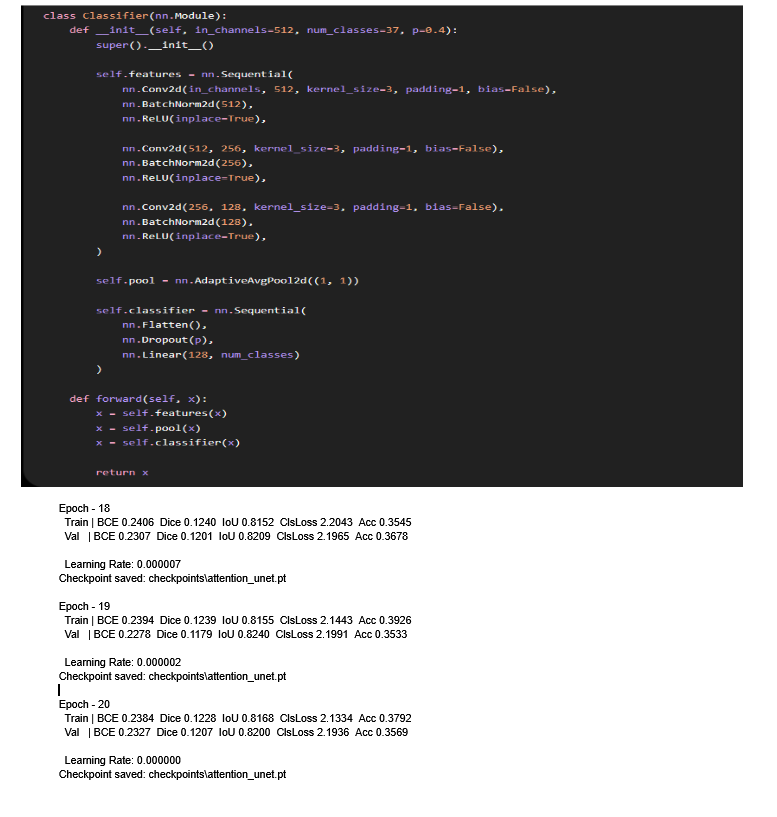

## 4. Final comparison — base U-Net vs Attention U-Net



In [56]:
attn_unet_results = {
    "train": evaluate(train_eval_loader, encoder_attn, bottleneck_attn, decoder_attn, classifier_attn),
    "val": evaluate(val_loader, encoder_attn, bottleneck_attn, decoder_attn, classifier_attn),
    "test": evaluate(test_loader, encoder_attn, bottleneck_attn, decoder_attn, classifier_attn),
}

rows = []
for split in ["train", "val", "test"]:
    for model_name, results in [("Base U-Net", base_unet_results), ("Attention U-Net", attn_unet_results)]:
        row = {"split": split, "model": model_name}
        row.update({k: round(v, 4) for k, v in results[split].items()})
        rows.append(row)

comparison_df = pd.DataFrame(rows)
comparison_df


,split,model,mIoU,Dice,PixelAcc,Accuracy,Precision,Recall,F1
0,train,Base U-Net,0.8419,0.9092,0.9323,0.8692,0.8754,0.8696,0.8691
1,train,Attention U-Net,0.8493,0.9140,0.9352,0.8833,0.8857,0.8837,0.8826
2,val,Base U-Net,0.8291,0.9000,0.9275,0.5707,0.5988,0.5714,0.5701
3,val,Attention U-Net,0.8351,0.9035,0.9290,0.5797,0.5975,0.5803,0.5785
4,test,Base U-Net,0.8213,0.8949,0.9213,0.5296,0.5486,0.5297,0.5292
5,test,Attention U-Net,0.8317,0.9016,0.9255,0.5358,0.5511,0.5356,0.5364


LOad MOdel


In [ ]:
#LOAD unet 
encoder = UNetEncoder(3, 32).to(device)
bottleneck = UNetBottleneck(256).to(device)
decoder = UNetDecoder(512).to(device)
classifier = Classifier(512, NUM_CLASSES).to(device)
CHECKPOINT_DIR = "checkpoints"
CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "base_unet.pt")
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device
)

encoder.load_state_dict(checkpoint['encoder'])
bottleneck.load_state_dict(checkpoint['bottleneck'])
decoder.load_state_dict(checkpoint['decoder'])
classifier.load_state_dict(checkpoint['classifier'])

print("Model checkpoint loaded successfully!")
print("Checkpoint epoch:", checkpoint['epoch'])

encoder.eval()
bottleneck.eval()
decoder.eval()
classifier.eval()
# **LOAD Attention U-Net


encoder_attn = UNetEncoder(3, 32).to(device)
bottleneck_attn = UNetBottleneck(256).to(device)
decoder_attn = AttentionUNetDecoder(512).to(device)
classifier_attn = Classifier(512, NUM_CLASSES).to(device)

CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "attention_unet.pt"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device
)

encoder_attn.load_state_dict(checkpoint['encoder'])
bottleneck_attn.load_state_dict(checkpoint['bottleneck'])
decoder_attn.load_state_dict(checkpoint['decoder'])
classifier_attn.load_state_dict(checkpoint['classifier'])

print("Attention U-Net checkpoint loaded successfully!")

encoder_attn.eval()
bottleneck_attn.eval()
decoder_attn.eval()
classifier_attn.eval()

In [45]:
from PIL import Image
import numpy as np
import torch
import matplotlib.pyplot as plt


def show_image_prediction(
    image_idx=None,
    x_data=None,
    mask_data=None,
    y_data=None,
    class_names=None,
    encoder=None,
    bottleneck=None,
    decoder=None,
    classifier=None,
    source=None
):
    # ------------------------------------------------------------
    # 1. GET IMAGE
    # ------------------------------------------------------------

    is_external = source is not None

    if is_external:
        if isinstance(source, str):
            image = Image.open(source).convert("RGB")
        else:
            image = source

        if isinstance(image, Image.Image):
            image = image.resize((128, 128))
            image = np.array(image).astype(np.float32) / 255.0
        else:
            image = np.asarray(image).astype(np.float32)

            if image.max() > 1:
                image = image / 255.0

            image = np.array(
                Image.fromarray(
                    (image * 255).astype(np.uint8)
                ).resize((128, 128))
            ).astype(np.float32) / 255.0

        display_image = image.copy()

        true_mask = None
        true_label = None

    else:
        if image_idx is None:
            raise ValueError(
                "Provide either image_idx or source."
            )

        image = x_data[image_idx]
        true_mask = mask_data[image_idx]
        true_label = y_data[image_idx]

        display_image = (
            image * train_std[0]
            + train_mean[0]
        )

        display_image = np.clip(
            display_image,
            0,
            1
        )

    # ------------------------------------------------------------
    # 2. PREPARE IMAGE FOR MODEL
    # ------------------------------------------------------------

    if is_external:
        image_mean = train_mean.squeeze()
        image_std = train_std.squeeze()

        image = (
            image - image_mean
        ) / image_std

    x = torch.tensor(
        image,
        dtype=torch.float32,
        device=device
    )

    x = x.permute(2, 0, 1).unsqueeze(0)

    # ------------------------------------------------------------
    # 3. MODEL PREDICTION
    # ------------------------------------------------------------

    encoder.eval()
    bottleneck.eval()
    decoder.eval()
    classifier.eval()

    with torch.no_grad():
        x1, x2, x3, x4 = encoder(x)

        x5 = bottleneck(x4)

        predicted_mask_logits = decoder(
            x5,
            x4,
            x3,
            x2,
            x1
        )

        predicted_label_logits = classifier(x5)

    # ------------------------------------------------------------
    # 4. PREDICTED MASK
    # ------------------------------------------------------------

    predicted_mask_prob = torch.sigmoid(
        predicted_mask_logits
    )

    predicted_mask = (
        predicted_mask_prob > 0.5
    ).float()

    predicted_mask = (
        predicted_mask[0]
        .cpu()
        .numpy()
    )

    # ------------------------------------------------------------
    # 5. PREDICTED CLASS
    # ------------------------------------------------------------

    predicted_label = (
        predicted_label_logits
        .argmax(dim=1)
        .item()
    )

    predicted_class = class_names[predicted_label]

    # ------------------------------------------------------------
    # 6. IOU
    # ------------------------------------------------------------

    if not is_external:
        true_mask_tensor = torch.tensor(
            true_mask,
            dtype=torch.float32,
            device=device
        ).unsqueeze(0)

        pred_binary = (
            predicted_mask_prob > 0.5
        ).float()

        pred_flat = pred_binary.view(1, -1)
        true_flat = true_mask_tensor.view(1, -1)

        intersection = (
            pred_flat * true_flat
        ).sum(dim=1)

        union = (
            pred_flat.sum(dim=1)
            + true_flat.sum(dim=1)
            - intersection
        )

        iou = (
            (intersection + 1e-6)
            / (union + 1e-6)
        ).item()

        original_class = class_names[true_label]

    # ------------------------------------------------------------
    # 7. DISPLAY
    # ------------------------------------------------------------

    if is_external:

        fig, axes = plt.subplots(
            1,
            2,
            figsize=(9, 4)
        )

        axes[0].imshow(display_image)
        axes[0].set_title("Input image")
        axes[0].axis("off")

        axes[1].imshow(display_image)
        axes[1].imshow(
            predicted_mask,
            cmap="Reds",
            alpha=0.45
        )
        axes[1].set_title(
            "Predicted mask overlay"
        )
        axes[1].axis("off")

        fig.suptitle(
            f'Predicted class: "{predicted_class}"',
            fontsize=14
        )

        plt.tight_layout()
        plt.show()

        print(f"Source: {source}")
        print(f"Predicted class: {predicted_class}")

    else:

        fig, axes = plt.subplots(
            1,
            3,
            figsize=(12, 4)
        )

        axes[0].imshow(display_image)
        axes[0].set_title("Original image")
        axes[0].axis("off")

        axes[1].imshow(display_image)
        axes[1].imshow(
            true_mask,
            cmap="Reds",
            alpha=0.45
        )
        axes[1].set_title(
            "True mask overlay"
        )
        axes[1].axis("off")

        axes[2].imshow(display_image)
        axes[2].imshow(
            predicted_mask,
            cmap="Reds",
            alpha=0.45
        )
        axes[2].set_title(
            "Predicted mask overlay"
        )
        axes[2].axis("off")

        fig.suptitle(
            f'Original: "{original_class}" | '
            f'Predicted: "{predicted_class}" | '
            f'IoU: {iou * 100:.1f}%',
            fontsize=14
        )

        plt.tight_layout()
        plt.show()

        print(f"Image index: {image_idx}")
        print(f"Original class: {original_class}")
        print(f"Predicted class: {predicted_class}")
        print(f"IoU: {iou:.4f} ({iou * 100:.2f}%)")

<>:19: SyntaxWarning: invalid escape sequence '\S'
<>:19: SyntaxWarning: invalid escape sequence '\S'
C:\Users\Admin\AppData\Local\Temp\ipykernel_15108\1283941051.py:19: SyntaxWarning: invalid escape sequence '\S'
  show_image_prediction( source="F:\Summer26\cse428\CSE428_Project\images.webp",


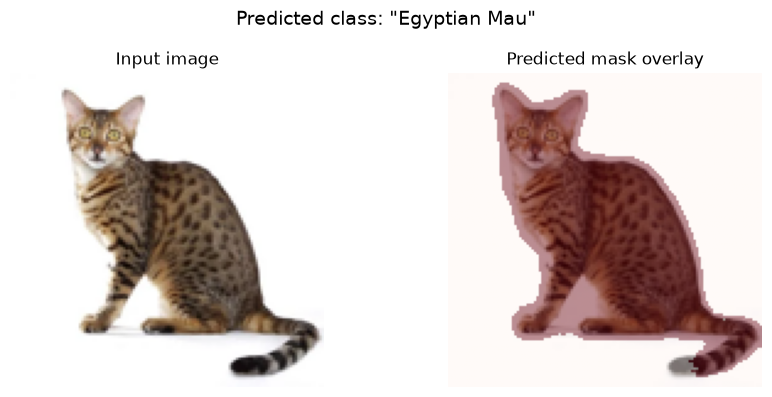

Source: egy.webp
Predicted class: Egyptian Mau


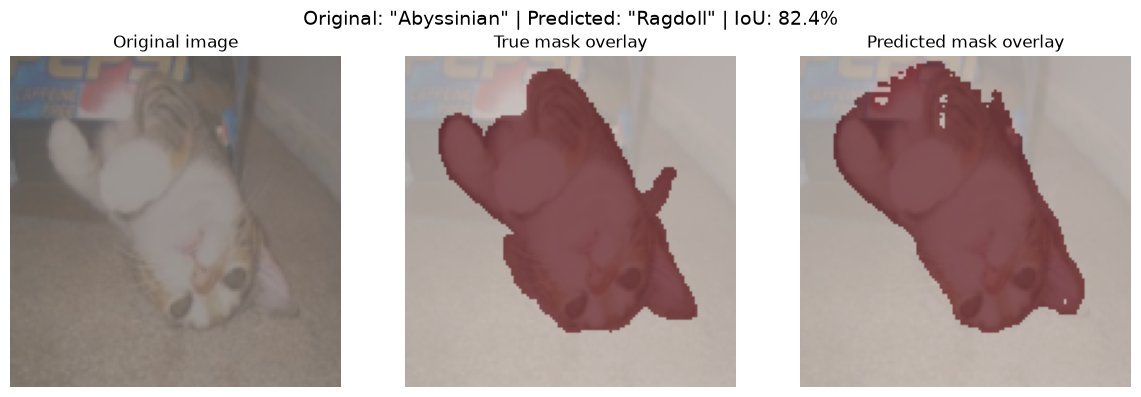

Image index: 10
Original class: Abyssinian
Predicted class: Ragdoll
IoU: 0.8239 (82.39%)


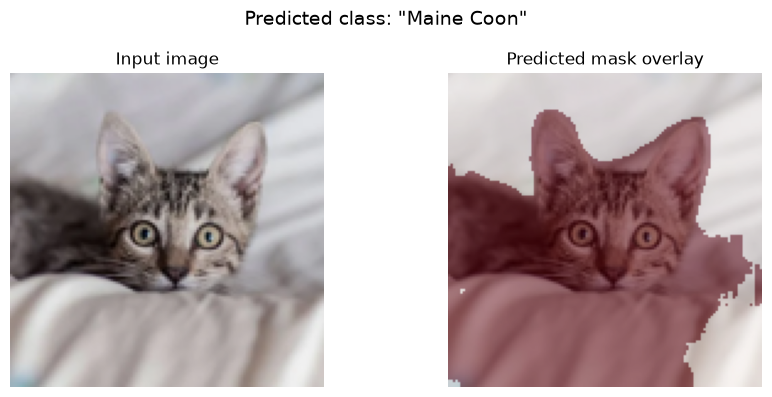

Source: F:\Summer26\cse428\CSE428_Project\images.webp
Predicted class: Maine Coon


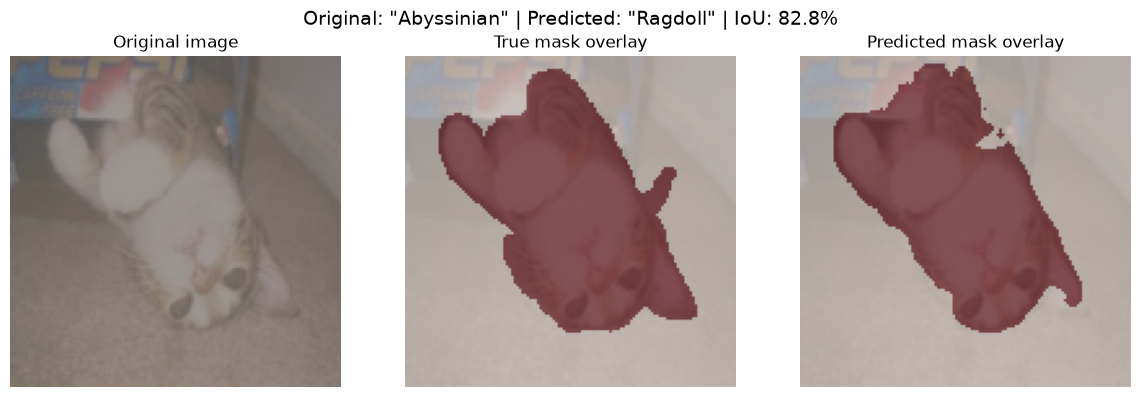

Image index: 10
Original class: Abyssinian
Predicted class: Ragdoll
IoU: 0.8284 (82.84%)


In [49]:
show_image_prediction( source="egy.webp", 
                      class_names=trainval_raw.classes, encoder=encoder_attn, 
                      bottleneck=bottleneck_attn, decoder=decoder_attn, classifier=classifier_attn) 
show_image_prediction(
    image_idx=10,
    x_data=x_test,
    mask_data=mask_test,
    y_data=y_test,
    class_names=trainval_raw.classes,
    encoder=encoder_attn,
    bottleneck=bottleneck_attn,
    decoder=decoder_attn,
    classifier=classifier_attn
)



#Attention unet
show_image_prediction( source="F:\Summer26\cse428\CSE428_Project\images.webp", 
                      class_names=trainval_raw.classes, encoder=encoder, 
                      bottleneck=bottleneck, decoder=decoder, classifier=classifier) 
show_image_prediction(
    image_idx=10,
    x_data=x_test,
    mask_data=mask_test,
    y_data=y_test,
    class_names=trainval_raw.classes,
    encoder=encoder,
    bottleneck=bottleneck,
    decoder=decoder,
    classifier=classifier
)



Test out different well-established classifier architectures (like MobileNet, EfficientNet, DenseNet etc.) and see how the performance changes. Show comparison between at least 3. (Difficulty: Medium)

In [ ]:
import torchvision.models as models
def build_classifier(arch_name, num_classes, pretrained=True):

    weights = 'DEFAULT' if pretrained else None 
    if arch_name == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights=weights)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
    elif arch_name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=weights)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
    elif arch_name == "densenet121":
        m = models.densenet121(weights=weights)
        m.classifier = nn.Linear(m.classifier.in_features, num_classes)
    else:
        raise ValueError(f"unknown architecture: {arch_name}")
    return m.to(device)
def train_classifier_only(model, train_loader, val_loader, epochs=15, lr=1e-4):
    optim = torch.optim.AdamW(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights) 

    for epoch in range(epochs):
        model.train()
        train_loader.iter = 0
        correct = samples = 0
        for i in range(train_loader.len):
            x, y_label = train_loader.next('classification')
            x = x.permute(0, 3, 1, 2)
            logits = model(x)
            loss = loss_fn(logits, y_label)
            optim.zero_grad(); loss.backward(); optim.step()
            correct += (logits.argmax(dim=1) == y_label).sum().item()
            samples += y_label.shape[0]
        train_acc = correct / samples

        model.eval()
        val_loader.iter = 0
        vcorrect = vsamples = 0
        with torch.no_grad():
            for i in range(val_loader.len):
                x, y_label = val_loader.next('classification')
                x = x.permute(0, 3, 1, 2)
                logits = model(x)
                vcorrect += (logits.argmax(dim=1) == y_label).sum().item()
                vsamples += y_label.shape[0]
        print(f"[{epoch+1}/{epochs}] train_acc {train_acc:.4f}  val_acc {vcorrect/vsamples:.4f}")
    return model
def evaluate_classifier_only(model, loader):
    model.eval()
    all_true, all_pred = [], []
    loader.iter = 0
    with torch.no_grad():
        for i in range(loader.len):
            x, y_label = loader.next('classification')
            x = x.permute(0, 3, 1, 2)
            logits = model(x)
            all_true.extend(y_label.cpu().numpy().tolist())
            all_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
    acc, precision, recall, f1 = classification_metrics(all_true, all_pred)
    return {"Accuracy": acc, "Precision": precision, "Recall": recall, "F1": f1}


architectures = ["mobilenet_v3_small", "efficientnet_b0", "densenet121"]
classifier_comparison = {}

for arch in architectures:
    print(f"\n=== Training {arch} ===")
    model = build_classifier(arch, NUM_CLASSES, pretrained=True)
    model = train_classifier_only(model, train_loader, val_loader, epochs=15, lr=1e-4)
    classifier_comparison[arch] = {
        "train": evaluate_classifier_only(model, train_eval_loader),
        "val": evaluate_classifier_only(model, val_loader),
        "test": evaluate_classifier_only(model, test_loader),
    }

rows = []
for split in ["train", "val", "test"]:
    ref = base_unet_results[split]
    rows.append({"split": split, "model": "Custom (Part 2)",
                 **{k: round(ref[k], 4) for k in ["Accuracy", "Precision", "Recall", "F1"]}})
    for arch in architectures:
        r = classifier_comparison[arch][split]
        rows.append({"split": split, "model": arch, **{k: round(v, 4) for k, v in r.items()}})

pd.DataFrame(rows)



=== Training mobilenet_v3_small ===
[1/15] train_acc 0.1288  val_acc 0.3442
[2/15] train_acc 0.4124  val_acc 0.5217
[3/15] train_acc 0.5508  val_acc 0.5870
[4/15] train_acc 0.6359  val_acc 0.6214
[5/15] train_acc 0.6797  val_acc 0.6649
[6/15] train_acc 0.7129  val_acc 0.6540
[7/15] train_acc 0.7510  val_acc 0.6594
[8/15] train_acc 0.7625  val_acc 0.6630
[9/15] train_acc 0.7983  val_acc 0.6703
[10/15] train_acc 0.8162  val_acc 0.6957
[11/15] train_acc 0.8347  val_acc 0.6685
[12/15] train_acc 0.8587  val_acc 0.6649
[13/15] train_acc 0.8696  val_acc 0.6866
[14/15] train_acc 0.8756  val_acc 0.6775
[15/15] train_acc 0.8919  val_acc 0.6793

=== Training efficientnet_b0 ===
[1/15] train_acc 0.2100  val_acc 0.5435
[2/15] train_acc 0.5729  val_acc 0.7391
[3/15] train_acc 0.7008  val_acc 0.7880


* * Bonus 4 — Hyperparameter Search: Optimizer × Learning Rate

In [28]:
train_loader = BatchLoaderAugmented(
    x_train,
    mask_train,
    y_train,
    shuffle=True,
    batch_size=BATCH_SIZE,
    device=device
)

val_loader = BatchLoader(
    x_val,
    mask_val,
    y_val,
    shuffle=False,
    batch_size=BATCH_SIZE,
    device=device
)

train_eval_loader = BatchLoader(
    x_train,
    mask_train,
    y_train,
    shuffle=False,
    batch_size=BATCH_SIZE,
    device=device
)

test_loader = BatchLoader(
    x_test_norm,
    mask_test,
    y_test,
    shuffle=False,
    batch_size=BATCH_SIZE,
    device=device
)
dice_loss = DiceLoss()
bce_loss = nn.BCEWithLogitsLoss()
class_weights = compute_class_weight(
    'balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

classifier_loss_fn = nn.CrossEntropyLoss(
    weight=class_weights
)

In [29]:
import itertools

optimizers_to_try = ["SGD", "Adam", "AdamW", "RMSprop"]
lrs_to_try = [1e-2, 1e-3, 1e-4, 1e-5]

def build_optimizer(name, params, lr):
    if name == "SGD":
        return torch.optim.SGD(params, lr=lr, momentum=0.9)   # momentum=0.9 is the standard default pairing
    elif name == "Adam":
        return torch.optim.Adam(params, lr=lr)
    elif name == "AdamW":
        return torch.optim.AdamW(params, lr=lr)
    elif name == "RMSprop":
        return torch.optim.RMSprop(params, lr=lr)
    raise ValueError(f"unknown optimizer: {name}")

def build_fresh_model():
    encoder = UNetEncoder(3, 32).to(device)
    bottleneck = UNetBottleneck(256).to(device)
    decoder = UNetDecoder(512).to(device)
    classifier = Classifier(512, NUM_CLASSES).to(device)
    params = list(encoder.parameters()) + list(bottleneck.parameters()) \
        + list(decoder.parameters()) + list(classifier.parameters())
    return encoder, bottleneck, decoder, classifier, params

search_epochs = 3
search_results = []

for opt_name, lr in itertools.product(optimizers_to_try, lrs_to_try):
    print(f"\n=== {opt_name}, lr={lr} ===")
    encoder, bottleneck, decoder, classifier, params = build_fresh_model()
    optim = build_optimizer(opt_name, params, lr)

    diverged = False
    for epoch in range(search_epochs):
        encoder.train(); decoder.train(); classifier.train()
        train_loader.iter = 0
        for i in range(train_loader.len):
            x, y_label, y_mask = train_loader.next('both')
            x = x.permute(0, 3, 1, 2)
            x1, x2, x3, x4 = encoder(x)
            x5 = bottleneck(x4)
            y_pred_mask = decoder(x5, x4, x3, x2, x1)
            y_pred_label = classifier(x5)
            loss = (0.2*bce_loss(y_pred_mask, y_mask) + 0.8*dice_loss(y_pred_mask, y_mask))/2 \
                + 0.5*classifier_loss_fn(y_pred_label, y_label)
            if torch.isnan(loss):
                diverged = True
                break
            optim.zero_grad(); loss.backward(); optim.step()
        if diverged:
            break

    if diverged:
        search_results.append({"optimizer": opt_name, "lr": lr, "val_mIoU": None, "val_acc": None,
                                "status": "diverged (NaN loss)"})
        print("  diverged -- skipping evaluation")
        continue

    encoder.eval(); decoder.eval(); classifier.eval()
    val_loader.iter = 0
    ious, correct, samples = [], 0, 0
    with torch.no_grad():
        for i in range(val_loader.len):
            x, y_label, y_mask = val_loader.next('both')
            x = x.permute(0, 3, 1, 2)
            x1, x2, x3, x4 = encoder(x)
            x5 = bottleneck(x4)
            y_pred_mask = decoder(x5, x4, x3, x2, x1)
            y_pred_label = classifier(x5)
            ious.append(calculate_iou(y_pred_mask, y_mask).item())
            correct += (y_pred_label.argmax(dim=1) == y_label).sum().item()
            samples += y_label.shape[0]

    val_miou, val_acc = np.mean(ious), correct/samples
    search_results.append({"optimizer": opt_name, "lr": lr, "val_mIoU": round(val_miou, 4),
                            "val_acc": round(val_acc, 4), "status": "ok"})
    print(f"  val mIoU {val_miou:.4f}  val acc {val_acc:.4f}")



    
search_df = pd.DataFrame(search_results)
converged = search_df[search_df["status"] == "ok"].sort_values("val_mIoU", ascending=False)
diverged = search_df[search_df["status"] != "ok"]

print("=== Converged configs, best first ===")
print(converged.to_string(index=False))
print("\n=== Diverged configs (excluded from ranking) ===")
print(diverged.to_string(index=False))

best_optimizer, best_lr = converged.iloc[0][["optimizer", "lr"]]
print(f"\nBest config from short search: {best_optimizer} @ lr={best_lr}")


=== SGD, lr=0.01 ===
  val mIoU 0.5839  val acc 0.0435

=== SGD, lr=0.001 ===
  val mIoU 0.4624  val acc 0.1359

=== SGD, lr=0.0001 ===
  val mIoU 0.3541  val acc 0.0616

=== SGD, lr=1e-05 ===
  val mIoU 0.1995  val acc 0.0254

=== Adam, lr=0.01 ===
  val mIoU 0.5672  val acc 0.0344

=== Adam, lr=0.001 ===
  val mIoU 0.5766  val acc 0.0326

=== Adam, lr=0.0001 ===
  val mIoU 0.6252  val acc 0.1667

=== Adam, lr=1e-05 ===
  val mIoU 0.6023  val acc 0.1069

=== AdamW, lr=0.01 ===
  val mIoU 0.5532  val acc 0.0616

=== AdamW, lr=0.001 ===
  val mIoU 0.5716  val acc 0.0471

=== AdamW, lr=0.0001 ===
  val mIoU 0.6322  val acc 0.1612

=== AdamW, lr=1e-05 ===
  val mIoU 0.6000  val acc 0.1087

=== RMSprop, lr=0.01 ===
  val mIoU 0.5337  val acc 0.0380

=== RMSprop, lr=0.001 ===
  val mIoU 0.5635  val acc 0.0525

=== RMSprop, lr=0.0001 ===
  val mIoU 0.6193  val acc 0.1612

=== RMSprop, lr=1e-05 ===
  val mIoU 0.5970  val acc 0.1087
=== Converged configs, best first ===
optimizer      lr  val